# Validation diagnostics — step 2
Run **`../TextExtractionPipeline.ipynb` with `SPLIT = "val"` first**. This notebook evaluates its saved, filtered and joined `candidates.jsonl`.

It does not run OCR, rebuild datasets, filter text, or join fragments. Reference transcripts are used only for comparison. Input candidates and upstream output files remain unchanged.


In [1]:
from pathlib import Path
import json
import sys

ROOT = next((candidate for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             for candidate in (base, base / "manga_notebook_codebase")
             if (candidate / "src/text_extraction_diagnostics.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Start this notebook inside the project or workspace")
sys.path.insert(0, str(ROOT / "src"))
from text_extraction_diagnostics import load_inputs, run_diagnostics
from data_utils import load_jsonl
from ocr_reports import get_ocr_result

split = 'val'
CANDIDATES_PATH = ROOT / f"outputs/text_extraction/{split}/candidates.jsonl"
OUTPUT = ROOT / f"outputs/diagnostics/ocr_joining_{split}"
SAMPLE = 4   # index within the saved extraction results, zero-based
PAGE = 0     # page within its three-page sequence, zero-based
print("Upstream results:", CANDIDATES_PATH)


Upstream results: C:\Users\ESHAAN\BYTE\Applied-Task\MultiModelSystem\manga_notebook_codebase\outputs\text_extraction\val\candidates.jsonl


## 1. Load and verify saved extraction results
Check candidate/audit hashes, saved split, image hashes, and source raw OCR hashes. The evaluated sequences must belong to validation. A limited validation extraction is supported, and coverage is reported explicitly. If upstream results are absent or stale, fix/rerun the extraction notebook first.


In [2]:
rows, candidates, raw, audit, references, metadata, _, total = load_inputs(ROOT, CANDIDATES_PATH)
print(f"Evaluating {len(rows)} of {total} validation sequences / {len(rows) * 3} pages")
print("Saved final groups:", sum(len(p) for r in candidates.values() for p in r["pages"]))
print("Upstream filtering settings:", metadata["config"])
print("Sound-word blacklist:", ", ".join(metadata.get("sound_effect_words", [])))


Evaluating 16 of 16 validation sequences / 48 pages
Saved final groups: 460
Upstream filtering settings: {'min_score': 0.0, 'max_gap': 1.25, 'center_tolerance': 1.5}
Sound-word blacklist: BAM, BANG, BOOM, BUZZ, BZZT, CLACK, CLANG, CLICK, CLUNK, CRACK, CRASH, CREAK, DING, DRIP, FWIP, KABOOM, POW, RUSTLE, SKRSH, SLAM, SMASH, SNAP, SPLASH, SWISH, SWOOSH, THUD, THUNK, TICK, TOCK, VROOM, WHACK, WHAM, WHOOSH, ZAP


## 2. Compare the exact saved groups with validation references
Matching is one-to-one fuzzy text comparison: threshold 0.5; high similarity 0.9. Similarity ignores punctuation and spacing. It does not establish correct balloon boundaries, speakers, or manga reading order.

Outputs: `allocations.jsonl`, `comparison.csv`, `summary.json`, HTML page reports, raw/final PNG previews, and readable transcripts. Group IDs, source IDs, boxes and text are taken from the pipeline output unchanged; references never replace extracted text. Diagnostics do not create a second `joined.jsonl`.


In [3]:
summary = run_diagnostics(ROOT, CANDIDATES_PATH, OUTPUT)
print(json.dumps(summary, indent=2))
print("Comparison CSV:", OUTPUT / "comparison.csv")
print("All-page report:", OUTPUT / "index.html")


{
  "sequences": 16,
  "validation_sequences_total": 16,
  "pages": 48,
  "raw_fragments": 1456,
  "proposed_groups": 460,
  "excluded_sound_effect_fragments": 9,
  "excluded_fragments": 12,
  "target_items": 328,
  "matched_targets": 318,
  "unmatched_groups": 142,
  "unmatched_targets": 10,
  "high_similarity_matches": 296,
  "matched_target_fraction": 0.9695121951219512,
  "mean_matched_similarity": 0.9829745030360735,
  "matching_threshold": 0.5,
  "high_similarity_threshold": 0.9,
  "input_candidates": "C:\\Users\\ESHAAN\\BYTE\\Applied-Task\\MultiModelSystem\\manga_notebook_codebase\\outputs\\text_extraction\\val\\candidates.jsonl",
  "input_candidates_sha256": "141621a16fbf63900f8b4188e4640615a0e84ffe0f89bee7a9022a9bf0084c68",
  "references_sha256": "c6be70ae6d3249d5a0dc01eb53c67175cc4e6624e83e03a37e60b752aea2372b",
  "pipeline_metadata_sha256": "733b10fe86d3f40b3b1b5732acc29165f9878e9bbced82f6ee30689e4e650a05",
  "diagnostics_code_sha256": "530fb703878b0812797dead41ea2a26742b06c

## 3. Inspect a page: raw OCR, final groups, exclusions, and reference matches
Change `SAMPLE` and `PAGE` above. The left image shows the original raw candidates; the right shows the exact filtered and joined pipeline groups. Excluded candidates are listed below, with their recorded reasons.


seq_b9b5a9ad9a64ced9 / page 0
Original raw OCR boxes:


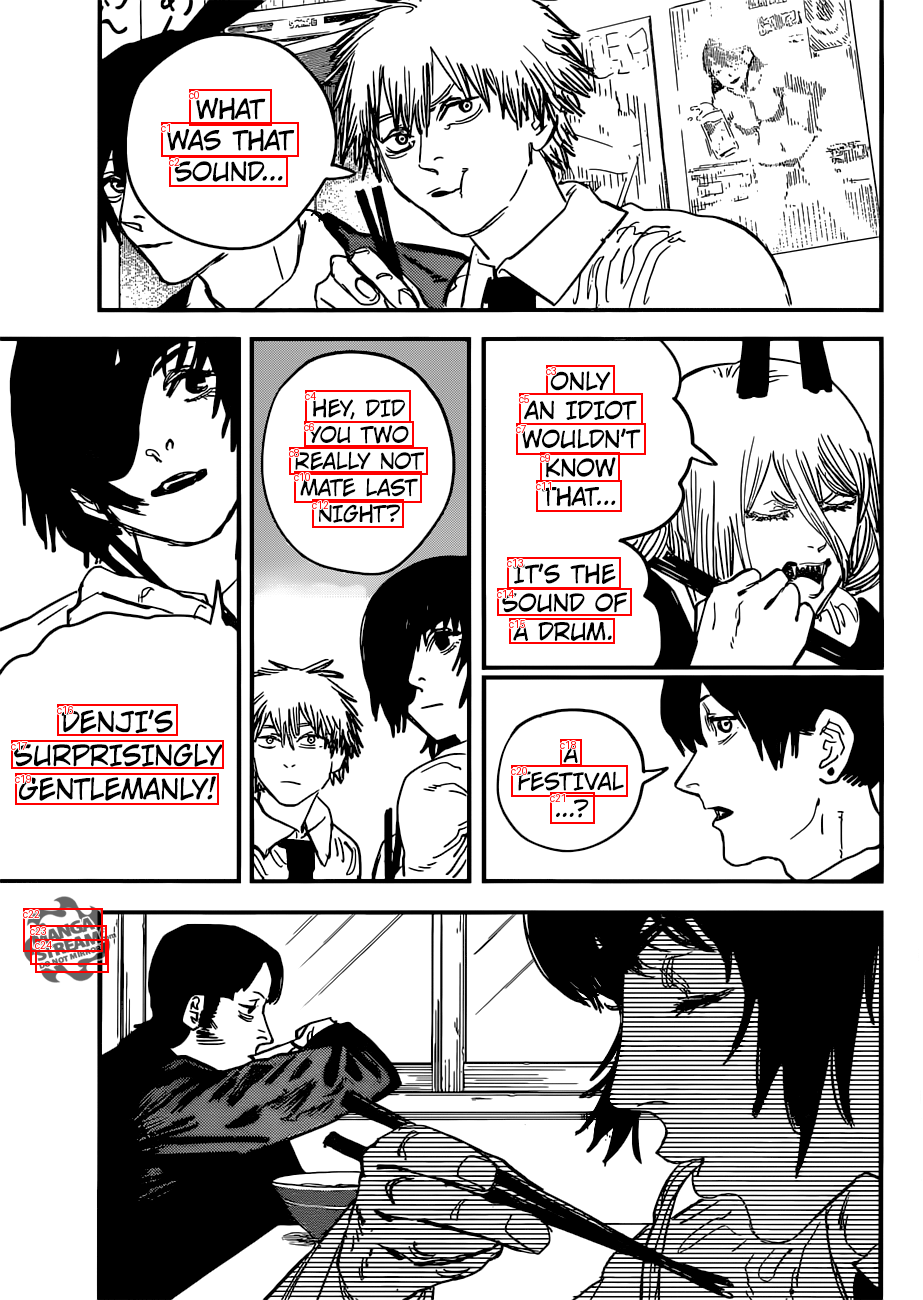

Final filtered and joined groups from TextExtractionPipeline:


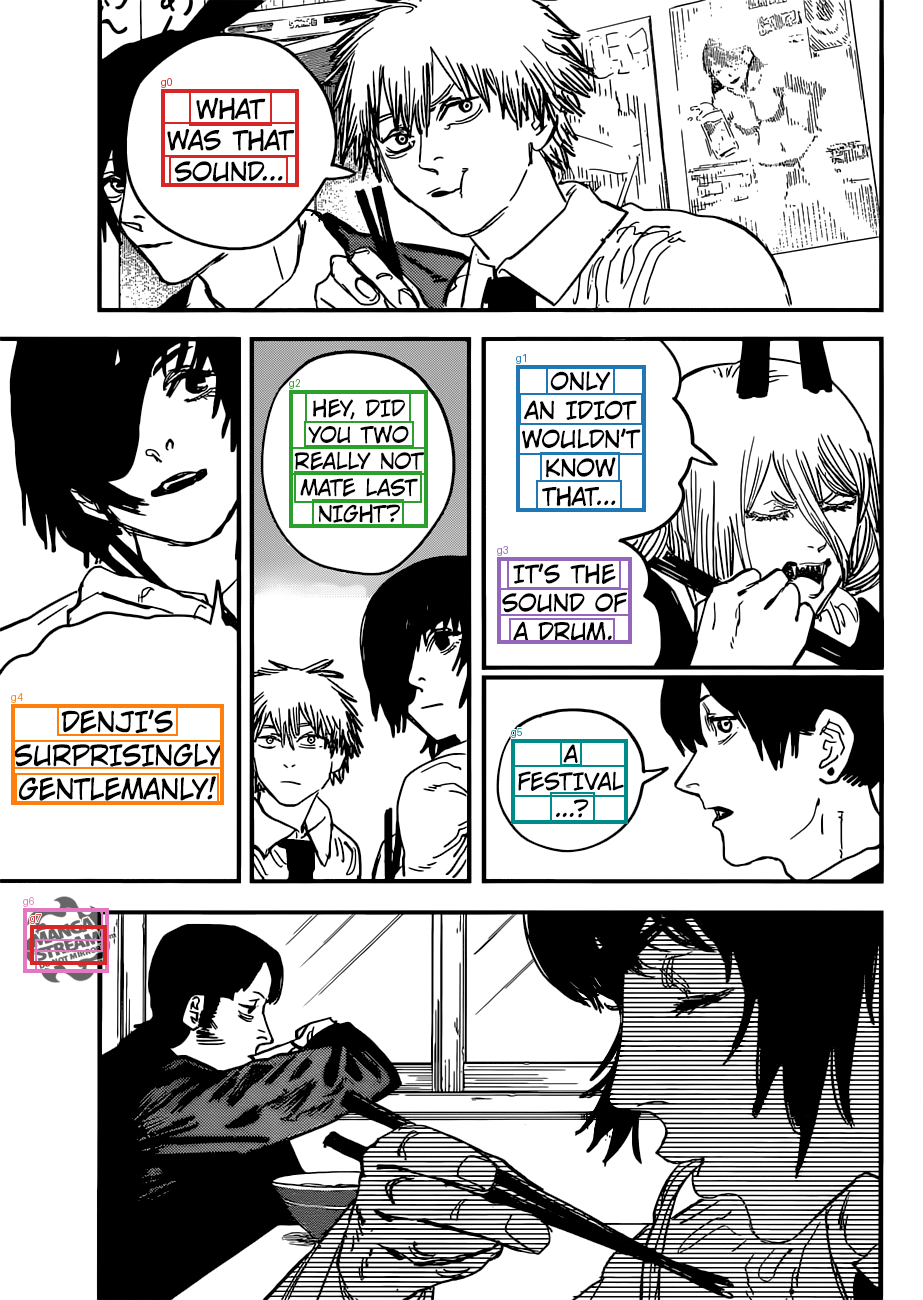

Group,Source OCR IDs,Extracted text,Target index,Reference text,Similarity
g0,"c0, c1, c2",WHAT WAS THAT SOUND...,0,WHAT WAS THAT SOUND...,1.0
g1,"c3, c5, c7, c9, c11",ONLY AN IDIOT WOULDN'T KNOW THAT...,1,ONLY AN IDIOT WOULDN'T KNOW THAT... IT'S THE SOUND OF A DRUM.,0.743
g2,"c4, c6, c8, c10, c12","HEY, DID YOU TWO REALLY NOT MATE LAST NIGHT?",3,"HEY, DID YOU TWO REALLY NOT MATE LAST NIGHT?",1.0
g3,"c13, c14, c15",IT'S THE SOUND OF A DRUM.,,,
g4,"c16, c17, c19",DENJI'S SURPRISINGLY GENTLEMANLY!,4,DENJI'S SURPRISINGLY GENTLEMANLY!,1.0
g5,"c18, c20, c21",A FESTIVAL ….?,2,A FESTIVAL...?,1.0
g6,"c22, c24",MANGA DO NOT MIRRORT,,,
g7,c23,STREAM,,,


Upstream exclusions:
[]
Saved preview: C:\Users\ESHAAN\BYTE\Applied-Task\MultiModelSystem\manga_notebook_codebase\outputs\diagnostics\ocr_joining_val\sample_3_page_0.html


In [5]:

import html
from IPython.display import display, HTML
from PIL import Image


SAMPLE = 3
if not 0 <= SAMPLE < len(rows) or not 0 <= PAGE < 3:
    raise ValueError("SAMPLE or PAGE is outside the saved results")
result = get_ocr_result(ROOT, sample=SAMPLE, page=PAGE, output=OUTPUT)
prefix = f"sample_{SAMPLE}_page_{PAGE}"
print(result["sequence_id"], "/ page", PAGE)
print("Original raw OCR boxes:")
with Image.open(OUTPUT / f"{prefix}_raw.png") as image:
    display(image.copy())
print("Final filtered and joined groups from TextExtractionPipeline:")
with Image.open(OUTPUT / f"{prefix}_groups.png") as image:
    display(image.copy())

columns = ["Group", "Source OCR IDs", "Extracted text", "Target index", "Reference text", "Similarity"]
values = [[g["id"], ", ".join(g["candidate_ids"]), g["text"], g["target_index"],
           g["target_text"], round(g["similarity"], 3) if g["similarity"] is not None else None]
          for g in result["groups"]]
values += [["Unmatched target", "", "", t["target_index"], t["text"], None]
           for t in result["unmatched_targets"]]
def escaped(value):
    return html.escape("" if value is None else str(value))
table = "<table><thead><tr>" + "".join(f"<th>{escaped(c)}</th>" for c in columns) + "</tr></thead><tbody>"
table += "".join("<tr>" + "".join(f"<td>{escaped(v)}</td>" for v in row) + "</tr>" for row in values)
display(HTML(table + "</tbody></table>"))
print("Upstream exclusions:")
print(json.dumps(result["filter_exclusions"], indent=2, ensure_ascii=False))
print("Saved preview:", result["preview_path"])
